# Chemeleon experiment results analysis 

(This is the main notebook for the final analysis after running all Chemeleon experiments on HPC)

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
import json
from pathlib import Path


In [2]:
results_df = pd.read_csv("results/chemeleon/run2_results_hpc/all_runs2.csv")
per_target_results = pd.read_csv("results/chemeleon/run2_results_hpc//per_target2.csv")

results_df = results_df.fillna('NA')
per_target_results = per_target_results.fillna("NA")

results_df.head(2)

,task,exp,seed,freeze_encoder,encoder_lr,head_lr,readout,hidden_dim,num_layers,dropout,...,lr_factor,lr_patience,val_score,baseline_score,best_epoch,epochs_run,final_score,train_loss_first,train_loss_last,overrides
0,classification,r2/01_frozen_linear,42,True,0.00001,0.001,linear,NA,NA,NA,...,0.5,2,0.149956,0.0,20,20,0.149956,0.533532,0.428361,model=chemeleon task=classification readout=li...
1,classification,r2/01_frozen_linear,43,True,0.00001,0.001,linear,NA,NA,NA,...,0.5,2,0.147442,0.0,19,20,0.103199,0.534993,0.427529,model=chemeleon task=classification readout=li...


In [3]:
per_target_results.head(2)

,task,exp,seed,target,MCC,AUROC,AP,n,positive_fraction,MAE,R2,ST-RAE
0,classification,r2/01_frozen_linear,42,CYP2D6_is_TDI,0.10759,0.685011,0.46434,230,0.273913,NA,NA,NA
1,classification,r2/01_frozen_linear,42,CYP3A4_is_TDI,0.192322,0.76887,0.450967,530,0.203774,NA,NA,NA


## Overall experiments summary

In [4]:
results_df.groupby("task").agg(
    runs = ("val_score", "size"),
    n_config = ("exp", "nunique"),
    n_seeds = ('seed', 'nunique'),
    min_score = ('val_score', 'min'),
    max_score = ("val_score",'max'),
    mean_score = ('val_score',"mean"),
    baseline_mean = ('baseline_score', 'mean')
)

,runs,n_config,n_seeds,min_score,max_score,mean_score,baseline_mean
task,,,,,,,
classification,39,13,3,0.143572,0.314833,0.264174,0.000000
regression,39,13,3,0.703773,0.750938,0.727459,0.983028


our experiments consisted of 78 runs - 39 per task with 13 unique configurations (repeated for each of the 3 seeds)

For classification we see quite a big spread of validation scores with min being 0.14 and max being 0.31. For regression the difference is not that significant. 

For both tasks Chemeleon scores are better than the naive baseline predictor.

## How the results between configurations differ?

Since in the current setup the model is non deterministic we repeated each experiment (configuration) on 3 seeds. Now we will test if the differences between configurations are significant, or are they comparable to the noise (as changing seeds). 

Anova one way test - H0: the distributions dont differ significantly.

In [5]:
regression_results = results_df[results_df['task']=='regression']
classification_results = results_df[results_df['task']=='classification']

Test for normality (Shapiro Wilk)

In [9]:
reg_residuals = regression_results['val_score'] - regression_results.groupby('exp')['val_score'].transform("mean")
print(len(reg_residuals))

print(stats.shapiro(reg_residuals))

39
ShapiroResult(statistic=np.float64(0.8702024133278461), pvalue=np.float64(0.000343060876850612))


In [11]:
cls_residuals = classification_results['val_score'] - classification_results.groupby('exp')['val_score'].transform("mean")
print(len(cls_residuals))

print(stats.shapiro(cls_residuals))

39
ShapiroResult(statistic=np.float64(0.9763503778173315), pvalue=np.float64(0.5724178135998201))


For classification the normality assumption is met (for ANOVA test) but for regression it is not

In [12]:
# regression ANova test switched for Kruskal Wallis

val_scores = []
unique_experiments = regression_results['exp'].unique()

for exp in unique_experiments:
    exp_column = regression_results[regression_results['exp']==exp]['val_score']
    val_scores.append(exp_column)
# test = stats.f_oneway(*val_scores)
# p_val = test.pvalue
# print(p_val)

print(stats.kruskal(*val_scores))

KruskalResult(statistic=np.float64(9.764102564102586), pvalue=np.float64(0.6366470979959671))


For regression we switched ANOVA to Kruskal test because the assumption about normal distribution was not met. The results are very similar so that there is no significant difference between groups.

In [13]:
# classif ANova test

val_scores = []
unique_experiments = classification_results['exp'].unique()

for exp in unique_experiments:
    exp_column = classification_results[classification_results['exp']==exp]['val_score']
    val_scores.append(exp_column)
test = stats.f_oneway(*val_scores)
p_val = test.pvalue
print(p_val)

1.755029969594786e-09


For classification p value = 0, which is a sign that different configurations produce significanly different validation scores.

## Best run and best configuration

#### Best single run

In [132]:
best_regression_score = regression_results['val_score'].min()
print("Best regression score : ", best_regression_score)

best_classification_score = classification_results['val_score'].max()
print("Best classification score: ", best_classification_score)

Best regression score :  0.7037734068569841
Best classification score:  0.3148326841405417


In [133]:
config_params = ['freeze_encoder', 'encoder_lr', 'head_lr', 'readout','hidden_dim', 'dropout','best_epoch','head_only_epochs']

In [134]:
best_reg_run = regression_results[regression_results['val_score']==best_regression_score][config_params]
best_reg_run

,freeze_encoder,encoder_lr,head_lr,readout,hidden_dim,dropout,best_epoch,head_only_epochs
48,False,0.00001,0.001,mlp,512.0,0.0,4,0


In [135]:
best_classif_run = classification_results[classification_results['val_score']== best_classification_score][config_params]
best_classif_run

,freeze_encoder,encoder_lr,head_lr,readout,hidden_dim,dropout,best_epoch,head_only_epochs
11,False,0.00001,0.001,mlp,512.0,0.0,7,0


The configuration of the best run is the same for classification and regression - MLP head, end to end finetuning with the same learning rates. Both of those runs reached their best score quite early during the training (epochs 4 and 7).

#### Best configurations

In [136]:
regression_best_config = regression_results.groupby('exp').val_score.agg('mean').idxmin()
print("regression best config (mean score)", regression_best_config)
regression_best_config_score = regression_results[regression_results['exp']==regression_best_config]['val_score'].mean()
print("score on the best config : ", regression_best_config_score)

print( " ---------------------------------------------------- ")
classif_best_config = classification_results.groupby('exp').val_score.agg("mean").idxmax()
print("Classification best config (mean score): ", classif_best_config)
classification_best_config_score = classification_results[classification_results['exp']==classif_best_config]['val_score'].mean()
print("score on the best config:", classification_best_config_score)

regression best config (mean score) r2/04_dropout03_mlp
score on the best config :  0.718461905691759
 ---------------------------------------------------- 
Classification best config (mean score):  r2/04_dropout01_mlp
score on the best config: 0.2918039554115906


In [137]:
# hyperparams of these configurations

regression_results[regression_results['exp'] == regression_best_config].iloc[0][config_params]

freeze_encoder       False
encoder_lr          0.0001
head_lr              0.001
readout                mlp
hidden_dim           512.0
dropout                0.3
best_epoch               6
head_only_epochs         5
Name: 66, dtype: object

In [138]:
classification_results[classification_results['exp']==classif_best_config].iloc[0][config_params]

freeze_encoder       False
encoder_lr          0.0001
head_lr              0.001
readout                mlp
hidden_dim           512.0
dropout                0.1
best_epoch              13
head_only_epochs         5
Name: 24, dtype: object

although the best run was on the same configuration, when looking at the mean scores on all seeds we see small differences. The best readout is still MLP with 512 neurons, but encoder learning rate is now 0.0001 with the warmup technique instead of end to end finetuning from the begnning.

**Best configuration improvement from the  naive baseline**

In [139]:
baseline_best_config_reg = regression_results[regression_results['exp']==regression_best_config]['baseline_score'].mean()
print("naive baseline - validation score (avg) on the best configuration for regression: ", baseline_best_config_reg-regression_best_config_score)

baseline_best_config_classif = classification_results[classification_results['exp']==classif_best_config]['baseline_score'].mean()
print("naive baseline - validation score (avg) on the best config for classification : ", baseline_best_config_classif - classification_best_config_score)

naive baseline - validation score (avg) on the best configuration for regression:  0.2645658975387615
naive baseline - validation score (avg) on the best config for classification :  -0.2918039554115906


# All configurations analysis 


Now we want to see how the choice of readout and freezing strategy influences the performance

In [140]:
def add_strategy(row):
    if row['freeze_encoder']==True:
        return "frozen"
    elif row['head_only_epochs']>0:
        return "warmup"
    else:
        return "end2end"

regression_results['strategy'] = regression_results.apply(add_strategy, axis=1)
classification_results['strategy'] = classification_results.apply(add_strategy, axis=1)

C:\Users\rogal\AppData\Local\Temp\ipykernel_11900\1716014096.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  regression_results['strategy'] = regression_results.apply(add_strategy, axis=1)
C:\Users\rogal\AppData\Local\Temp\ipykernel_11900\1716014096.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  classification_results['strategy'] = classification_results.apply(add_strategy, axis=1)


In [141]:
regression_results.head(1)

,task,exp,seed,freeze_encoder,encoder_lr,head_lr,readout,hidden_dim,num_layers,dropout,...,lr_patience,val_score,baseline_score,best_epoch,epochs_run,final_score,train_loss_first,train_loss_last,overrides,strategy
39,regression,r2/01_frozen_linear,42,True,0.00001,0.001,linear,NA,NA,NA,...,2,0.744778,0.983028,17,20,0.7581,0.938563,0.51874,model=chemeleon task=regression readout=linear...,frozen


In [142]:
regression_results['method'] = regression_results['strategy'] + " + " + regression_results['readout']
classification_results['method'] = classification_results['strategy'] + " + " + classification_results['readout']

C:\Users\rogal\AppData\Local\Temp\ipykernel_11900\923578401.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  regression_results['method'] = regression_results['strategy'] + " + " + regression_results['readout']
C:\Users\rogal\AppData\Local\Temp\ipykernel_11900\923578401.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  classification_results['method'] = classification_results['strategy'] + " + " + classification_results['readout']


In [143]:
palette = {
    "frozen + linear": "#4477AA",
    "frozen + mlp": "#ABCDE0",
    "end2end + linear": "#508A68",
    "end2end + mlp": "#9DD1B1",
    "warmup + linear": "#AA3377",
    "warmup + mlp": "#E0ABD8"
}


short_labels = {
    'r2/01_frozen_linear' : "frozen_linear",
    'r2/01_frozen_mlp' : " frozen_mlp",
    'r2/02_unfrozen_linear' : "unfozen_linear",
    'r2/02_unfrozen_mlp' : "unfrozen_mlp",
    'r2/03_warmup_lr1e-4_linear': "warmup_linear_lr1e-4",
    'r2/03_warmup_lr1e-4_mlp': "warmup_mlp_lr1e-4", 
    'r2/03_warmup_lr1e-5_linear': "warmup_linear_lr1e-5",
    'r2/03_warmup_lr1e-5_mlp' : "warmup_mlp_lr1e-5",
    'r2/04_dropout01_mlp': "mlp_droupout01",
    'r2/04_dropout03_mlp': "mlp_droupout03", 
    'r2/05_wd1e-2_mlp': "mlp_weightdecay1e-2", 
    'r2/05_wd1e-4_mlp': "mlp_weightdecay1e-4",
    'r2/06_reduce_lr_mlp': "mlp_reduce_lr"
}


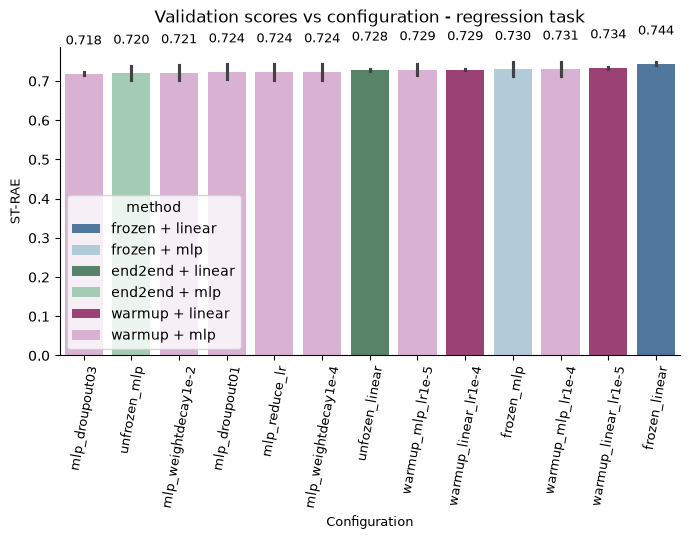

In [144]:
order = regression_results.groupby('exp')['val_score'].mean().sort_values(ascending=True).index.to_list()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=regression_results, x='exp', y='val_score',errorbar='sd',hue='method', order=order,palette=palette, ax=ax )

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=19, fontsize=9)
labels = [short_labels.get(x, x) for x in order]

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=80, fontsize=9)

ax.set_xlabel("Configuration", fontsize=9)
ax.set_ylabel("ST-RAE", fontsize = 9)
ax.set_title("Validation scores vs configuration - regression task", pad=18)
sns.despine(ax=ax)

fig.savefig("figures/regression_all_results.pdf", format="pdf", bbox_inches="tight")

plt.show()


For regression task the worst performing configurations were frozen and warmup linear and the best were warmup/end to end MLP heads. We see that end to end linear configuration was outperforming some MLP heads.

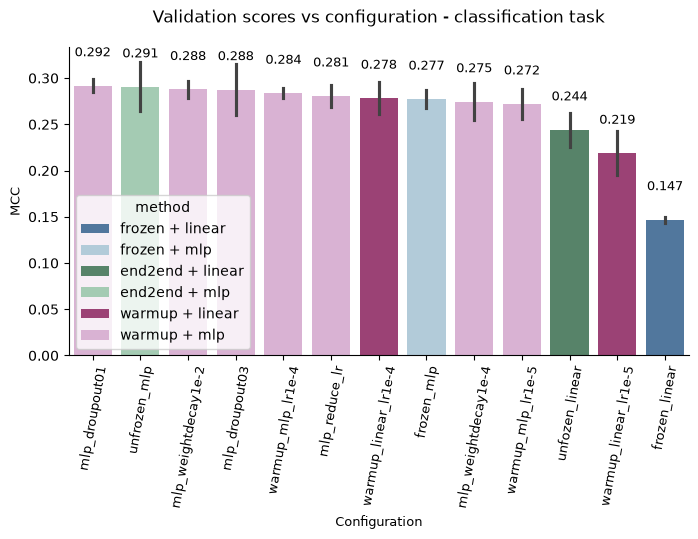

In [145]:
order = classification_results.groupby('exp')['val_score'].mean().sort_values(ascending=False).index.to_list()

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=classification_results, x='exp', y='val_score',errorbar='sd',hue='method', order=order,palette=palette, ax=ax )

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=19, fontsize=9)
labels = [short_labels.get(x, x) for x in order]

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=80, fontsize=9)

ax.set_xlabel("Configuration", fontsize=9)
ax.set_ylabel("MCC", fontsize = 9)
ax.set_title("Validation scores vs configuration - classification task", pad=18)
sns.despine(ax=ax)

fig.savefig("figures/classification_all_results.pdf", format="pdf", bbox_inches="tight")

plt.show()


For classification the best results are also for warmup and end to end MLP heads. The frozen linear is significantly lower than other configurations. Here the warmup linear was also outperforming some MLP configurations.

**COnclusions**:

1. MLP readout is the winning architecture for both tasks

2. End to end and warmup strategies outperform freezing - the model benefits from some additional training on the new data

3. frozen linear head and warmup with very small lr are the 2 worst configurations. 

4. For both tasks the frozen architecture is the underperforming one. 

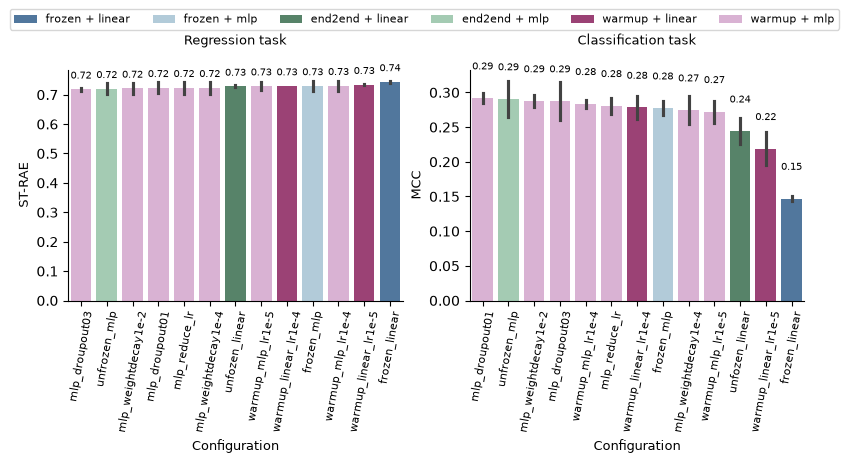

In [146]:
# join both plots to fit on the report 
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3))
order_reg = regression_results.groupby('exp')['val_score'].mean().sort_values().index.to_list()

sns.barplot(data=regression_results, x='exp', y='val_score',errorbar='sd',hue='method', order=order_reg,palette=palette, ax=axes[0] )

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f", padding=6, fontsize=7)
labels = [short_labels.get(x, x) for x in order_reg]

axes[0].set_xticks(range(len(labels)))
axes[0].set_xticklabels(labels, rotation=80, fontsize=8)

axes[0].set_xlabel("Configuration", fontsize=9)
axes[0].set_ylabel("ST-RAE", fontsize = 9)
axes[0].set_title("Regression task", pad=18, fontsize=9)
sns.despine(ax=axes[0])

#classification 

order_cls = classification_results.groupby('exp')['val_score'].mean().sort_values(ascending=False).index.to_list()

sns.barplot(data=classification_results, x='exp', y='val_score',errorbar='sd',hue='method', order=order_cls,palette=palette, ax=axes[1] )

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", padding=19, fontsize=7)
labels = [short_labels.get(x, x) for x in order_cls]

axes[1].set_xticks(range(len(labels)))
axes[1].set_xticklabels(labels, rotation=80, fontsize=8)

axes[1].set_xlabel("Configuration", fontsize=9)
axes[1].set_ylabel("MCC", fontsize = 9)
axes[1].set_title("Classification task", pad=18, fontsize=9)
sns.despine(ax=axes[1])

handles, legend_labels = axes[0].get_legend_handles_labels()
axes[0].get_legend().remove()
axes[1].get_legend().remove()

fig.legend(
    handles,
    legend_labels,
    loc='upper center',
    ncol=len(legend_labels),
    fontsize=8,
    bbox_to_anchor=(0.5, 1.1)
)

fig.savefig(
    "figures/classification_regression_combined.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()



Does unfreezing help ? (overall scores comparison - on all configurations)

In [147]:
print(regression_results.groupby(['strategy','readout']).val_score.agg('mean'))

print("------------------------")

print(classification_results.groupby(['strategy', 'readout']).val_score.agg('mean'))

strategy  readout
end2end   linear     0.728117
          mlp        0.720371
frozen    linear     0.743668
          mlp        0.729893
warmup    linear     0.731794
          mlp        0.724475
Name: val_score, dtype: float64
------------------------
strategy  readout
end2end   linear     0.244072
          mlp        0.290569
frozen    linear     0.146990
          mlp        0.277317
warmup    linear     0.248566
          mlp        0.282597
Name: val_score, dtype: float64


For regression the scores are very similar regardless of the strategy, suggesting that frozen vs end to end does not change the results much (is aligned with the ANOVA test finding as well).

However, for classification we see large differences, specifically with different strategies on linear head, where end to end/warmup is much better than freezing. 

**Conclusion** : For classification unfreezing the encoder makes the biggest difference, especially for linear head meaning that MLP is able to better use the pre trained representations, while linear head highly benefits from additional training of the encoder.

## Best training epoch analysis

C:\Users\rogal\AppData\Local\Temp\ipykernel_23176\1286605071.py:4: UserWarning: The palette list has more values (9) than needed (2), which may not be intended.
  sns.histplot(


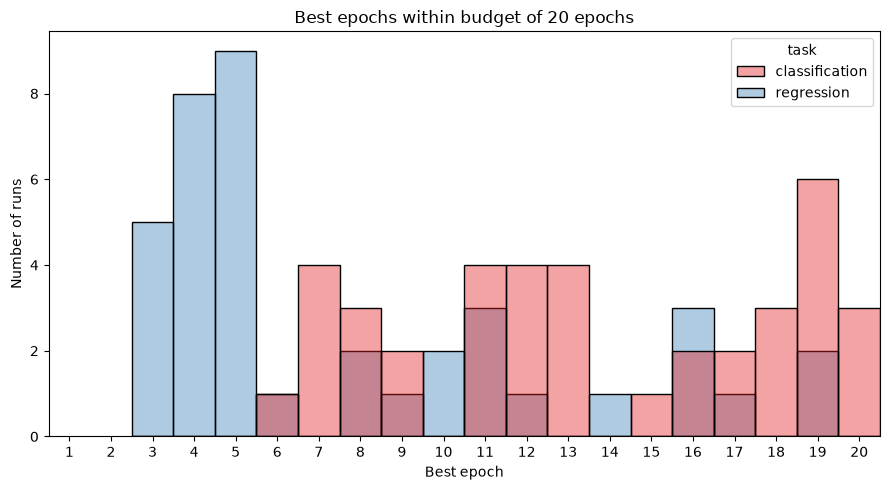

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
palette = sns.color_palette("Set1")

sns.histplot(
    data=results_df,
    x="best_epoch",
    hue="task",
    discrete=True,
    alpha=0.4,
    ax=ax,
    palette = palette
)


ax.set_xticks(range(1, 21))
ax.set_xlim(0.5, 20.5)
ax.set_xlabel("Best epoch")
ax.set_ylabel("Number of runs")
ax.set_title("Best epochs within budget of 20 epochs")

plt.tight_layout()

fig.savefig(
    "figures/best_epochs.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()

For regression the model tends to overfit quickly - the best epochs are usually very early (3-5 epoch), while for classification many runs seem to be terminated too quickly. (20 epochs may not be enough)

Lets see the configurations where the best epoch was 19:

In [149]:
classification_results[classification_results['best_epoch']==19]['exp']

1            r2/01_frozen_linear
2            r2/01_frozen_linear
6          r2/02_unfrozen_linear
7          r2/02_unfrozen_linear
19    r2/03_warmup_lr1e-5_linear
27           r2/04_dropout03_mlp
Name: exp, dtype: object

This happens mostly for linear heads (which had poor results) and in one run for the MLP head. 

We repeated the experiments : r2/02_unfrozen_linear (from the experiments above), and r2/02_dropout01_mlp (as the best configuration for classification)

### New results on the repeated experiments

In [150]:
longer_runs = pd.read_csv("results/chemeleon/run2_results_hpc/classification_100.csv")
configuration_names = {
    "r2/100ep_unfrozen_linear": "Linear head end2end",
    "r2/100ep_dropout01_mlp": "MLP head, dropout 0.1 warmup",
}
longer_runs["configuration"] = longer_runs["exp"].map(configuration_names)

longer_runs[
    [
        "configuration",
        "seed",
        "best_mcc_20",
        "best_epoch_20",
        "best_mcc_100",
        "best_epoch_100",
        "improvement",
    ]
].round(4)

,configuration,seed,best_mcc_20,best_epoch_20,best_mcc_100,best_epoch_100,improvement
0,Linear head end2end,42,0.2188,19,0.2962,72,0.0774
1,Linear head end2end,43,0.2592,19,0.2933,96,0.0340
2,Linear head end2end,44,0.2484,18,0.2780,91,0.0296
3,"MLP head, dropout 0.1 warmup",42,0.2794,19,0.3164,33,0.0371
4,"MLP head, dropout 0.1 warmup",43,0.3000,13,0.3119,28,0.0119
5,"MLP head, dropout 0.1 warmup",44,0.2789,7,0.3101,31,0.0312


We can see that the linear head benefited from additional training time - the best epochs were still near the end of the epoch budget, while for the MLP head the best epoch was around the 30th. 

We can see some improvements in the scores, however they are not that significant. 

#### Average change across all 3 seeds

The table below averages the best scores from each run. The improvement is the difference between the two scores. It is an MCC change, not an accuracy percentage

In [151]:
epoch_summary = longer_runs.groupby("configuration", sort=False)[
    ["best_mcc_20", "best_mcc_100", "improvement"]
].mean()
epoch_summary.round(4)

,best_mcc_20,best_mcc_100,improvement
configuration,,,
Linear head end2end,0.2421,0.2892,0.0470
"MLP head, dropout 0.1 warmup",0.2861,0.3128,0.0267


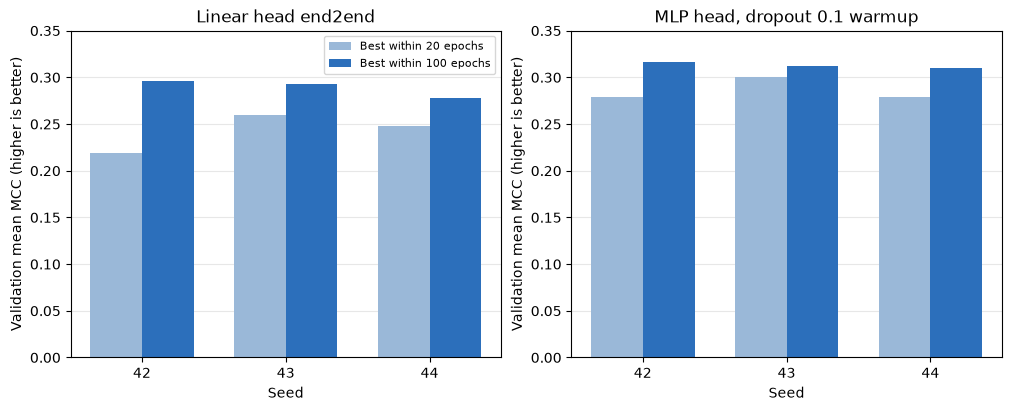

In [152]:
epoch_fig, epoch_axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")

for epoch_ax, configuration in zip(epoch_axes, configuration_names.values()):
    seed_results = longer_runs[longer_runs["configuration"] == configuration].sort_values("seed")
    positions = np.arange(len(seed_results))

    epoch_ax.bar(
        positions - 0.18,
        seed_results["best_mcc_20"],
        width=0.36,
        label="Best within 20 epochs",
        color="#9ab8d8",
    )
    epoch_ax.bar(
        positions + 0.18,
        seed_results["best_mcc_100"],
        width=0.36,
        label="Best within 100 epochs",
        color="#2c6fbb",
    )
    epoch_ax.set_xticks(positions, seed_results["seed"])
    epoch_ax.set_xlabel("Seed")
    epoch_ax.set_ylabel("Validation mean MCC (higher is better)")
    epoch_ax.set_ylim(0, 0.35)
    epoch_ax.set_title(configuration)
    epoch_ax.grid(axis="y", alpha=0.3)
    epoch_ax.set_axisbelow(True)

epoch_axes[0].legend(fontsize=8)
plt.show()

What did longer training show?

* Linear head : the avg best MCC increased from 0.24 to 0.29 and the best epochs were 72,91,96 (still late in the training, but not at the last epoch)

* MLP head : the avg best MCC increased from 0.29 to 0.31 and the best epochs were near epoch 30.

The linear head needs more training but still scores below MLP head. 

**Since the performance gain was more significant for the linear head (and not for the winning configuration), we treat this as an additional check confirming that setting a budget of 20 epochs may be a militation of this project. However, to stay consistent we will continue with the models trained on 20 epochs for the rest of the project.**



# Per target analysis

Lets see how each of the targets affects the macro performance for the best configurations.

In [153]:
classif_best_config

'r2/04_dropout01_mlp'

In [154]:
regression_best_config

'r2/04_dropout03_mlp'

#### Classification per target

In [155]:
classif_per_target = per_target_results[(per_target_results['task']=='classification') & (per_target_results['exp']==classif_best_config)]

classif_per_target.groupby('target').agg(mean_mcc = ("MCC","mean"), std = ("MCC", "std"), num_seeds = ("seed", "size"))

,mean_mcc,std,num_seeds
target,,,
CYP2D6_is_TDI,0.228001,0.014482,3
CYP3A4_is_TDI,0.355607,0.011544,3


There is a big difference between mean MCC scores for CYP2D6 and CYP3A4. One hypothesis is that it can be due to less non-null training examples of CYP2D6. Lets check that:

In [156]:
train_df = pd.read_csv("../data/classification/train.csv")
cyp2d6_count = len(train_df[~train_df['CYP2D6_is_TDI'].isna()])
cyp3a4_count = len(train_df[~train_df['CYP3A4_is_TDI'].isna()])

print("Number of valid CYP2D6 training samples : ", cyp2d6_count)
print("Number of valid CYP3A4 training samples: ", cyp3a4_count)

Number of valid CYP2D6 training samples :  1045
Number of valid CYP3A4 training samples:  2516


There are almost twice as many CYP3A4 training samples as CYP2D6. This could be one reason for the worse performance on this target. Second reason could be just that this target is more difficult to learn for the model.

#### Regression per target

In [157]:
reg_per_target = per_target_results[(per_target_results['task']=='regression') & (per_target_results['exp']==regression_best_config)]

reg_per_target.groupby('target').agg(mean_strae = ("ST-RAE","mean"), std = ("ST-RAE", "std"), num_seeds = ("seed", "size")).sort_values("mean_strae")

,mean_strae,std,num_seeds
target,,,
CYP3A4_pIC50_direct_inhibition,0.453138,0.022190,3
CYP2C9_pIC50_direct_inhibition,0.571815,0.035787,3
CYP1A2_pIC50_direct_inhibition,0.907599,0.030479,3
CYP2D6_pIC50_direct_inhibition,0.941295,0.028216,3


for regression we also see target differences, let's check if the reason can also be the number of training samples. the best two targets are CYP3A4 (the same as for classification) and CYP2C9, while CYP2D6 here is also the worst performing one. 

In [158]:
train_df = pd.read_csv("../data/regression/train.csv")
cyp1A2_count = len(train_df[~train_df['CYP1A2_pIC50_direct_inhibition'].isna()])
cyp2C9_count = len(train_df[~train_df['CYP2C9_pIC50_direct_inhibition'].isna()])
cyp2D6_count = len(train_df[~train_df['CYP2D6_pIC50_direct_inhibition'].isna()])
cyp3A4_count = len(train_df[~train_df['CYP3A4_pIC50_direct_inhibition'].isna()])

print("Number of valid CYP3A4 training samples: ", cyp3A4_count)
print("Number of valid CYP2C9 training samples", cyp2C9_count)
print("Number of valid CYP1A2 training samples", cyp1A2_count)
print("Number of valid CYP2D6 training samples : ", cyp2D6_count)



Number of valid CYP3A4 training samples:  1624
Number of valid CYP2C9 training samples 877
Number of valid CYP1A2 training samples 973
Number of valid CYP2D6 training samples :  1041


Here this hypothesis does not hold, CYP2D6 although having almost the biggest number of samples is still the worst performing one.

**Conslusion from per target analysis** : CYP2D6 is the hardes target for the model on both tasks. For classification it could be a consequence of sparse data, however for regression it cannot be justified that way. 

CYP3A4 is the easiest one for the model - performing the best for both classification and resgression

# Test results 

After choosing the best configuration we test the model on the unseen test dataset. 

Best configuration for regression was : MLP head with 0.3 dropout and warmup 

Best configuration for classification was : MLP head with 0.1 dropout and warmup 


In [159]:
regression_test_path = Path("results/chemeleon/run2_results_hpc/test_metrics_regression_run2.json")
classif_test_path = Path("results/chemeleon/run2_results_hpc/test_metrics_classification_run2.json")

reg_test_results = json.loads(regression_test_path.read_text())
reg_test_results["macro"] = reg_test_results.pop("macro_ST-RAE")

cls_test_results = json.loads(classif_test_path.read_text())
cls_test_results["macro"] = cls_test_results.pop("macro_MCC")

Regression validation vs test

In [160]:
# regression valid score for the winning config
reg_grouped = per_target_results[(per_target_results['task']=='regression') & (per_target_results['exp'] == regression_best_config)].groupby('target', as_index=False).agg(mean_strae=('ST-RAE', 'mean'))
reg_grouped = reg_grouped[['target', 'mean_strae']]

macro_score_best_config = pd.DataFrame([{"target": "macro", "mean_strae": regression_best_config_score}])

reg_final = pd.concat([reg_grouped, macro_score_best_config])

reg_final

,target,mean_strae
0,CYP1A2_pIC50_direct_inhibition,0.907599
1,CYP2C9_pIC50_direct_inhibition,0.571815
2,CYP2D6_pIC50_direct_inhibition,0.941295
3,CYP3A4_pIC50_direct_inhibition,0.453138
0,macro,0.718462


In [161]:
df_reg_test = pd.DataFrame(reg_test_results).drop(columns="macro").loc["ST-RAE"].reset_index()
df_reg_test.columns = ["target", "ST-RAE_test"]

macro_score_test = pd.DataFrame([{"target": "macro", "ST-RAE_test": reg_test_results['macro']}])

reg_test_final = pd.concat([df_reg_test, macro_score_test])

reg_test_final

,target,ST-RAE_test
0,CYP1A2_pIC50_direct_inhibition,0.843613
1,CYP2C9_pIC50_direct_inhibition,0.725183
2,CYP2D6_pIC50_direct_inhibition,0.962512
3,CYP3A4_pIC50_direct_inhibition,0.493852
0,macro,0.756290


In [162]:
reg_merged = reg_final.merge(reg_test_final,how='left', on='target')
reg_merged

,target,mean_strae,ST-RAE_test
0,CYP1A2_pIC50_direct_inhibition,0.907599,0.843613
1,CYP2C9_pIC50_direct_inhibition,0.571815,0.725183
2,CYP2D6_pIC50_direct_inhibition,0.941295,0.962512
3,CYP3A4_pIC50_direct_inhibition,0.453138,0.493852
4,macro,0.718462,0.756290


For regression the test scores are worse than validation for all targets except CYP1A2

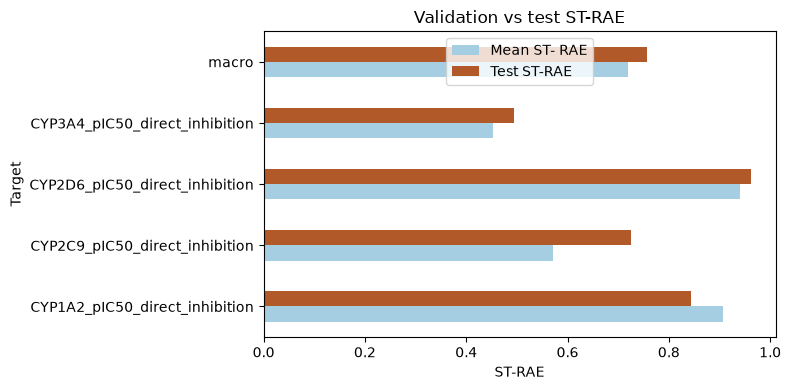

In [163]:
ax = reg_merged.set_index('target')[['mean_strae', 'ST-RAE_test']].plot(
    kind='barh',
    figsize=(8, 4),
    width=0.5,
    colormap='Paired'
)
ax.set_xlabel('ST-RAE')
ax.set_ylabel('Target')
ax.set_title("Validation vs test ST-RAE")
ax.legend(
    ['Mean ST- RAE', 'Test ST-RAE'],
    loc='upper center'
)
plt.tight_layout()
plt.show()

Classification:

In [164]:
df_cls_test = pd.DataFrame(cls_test_results).drop(columns="macro").loc["MCC"].reset_index()
df_cls_test.columns = ["target", "MCC_test"]

df_macro_test = pd.DataFrame([{"target": "macro", "MCC_test": cls_test_results['macro']}])

final_test_cls = pd.concat([df_cls_test, df_macro_test])

final_test_cls


,target,MCC_test
0,CYP2D6_is_TDI,0.025035
1,CYP3A4_is_TDI,0.339702
0,macro,0.182368


In [165]:
cls_grouped = per_target_results[(per_target_results['task']=='classification') & (per_target_results['exp'] == classif_best_config)].groupby('target', as_index=False).agg(mean_mcc=('MCC', 'mean'))
cls_grouped = cls_grouped[['target', 'mean_mcc']]

cls_valid_macro = pd.DataFrame([{"target":"macro", "mean_mcc": classification_best_config_score}])

cls_valid_final = pd.concat([cls_grouped, cls_valid_macro])
cls_valid_final

,target,mean_mcc
0,CYP2D6_is_TDI,0.228001
1,CYP3A4_is_TDI,0.355607
0,macro,0.291804


In [166]:
cls_merged = cls_valid_final.merge(final_test_cls,how='left', on='target')
cls_merged

,target,mean_mcc,MCC_test
0,CYP2D6_is_TDI,0.228001,0.025035
1,CYP3A4_is_TDI,0.355607,0.339702
2,macro,0.291804,0.182368


CYP2D6 completely failed during testing (MCC from 0.23 to 0.03), while CYP3A4 was only a little worse than on validation.

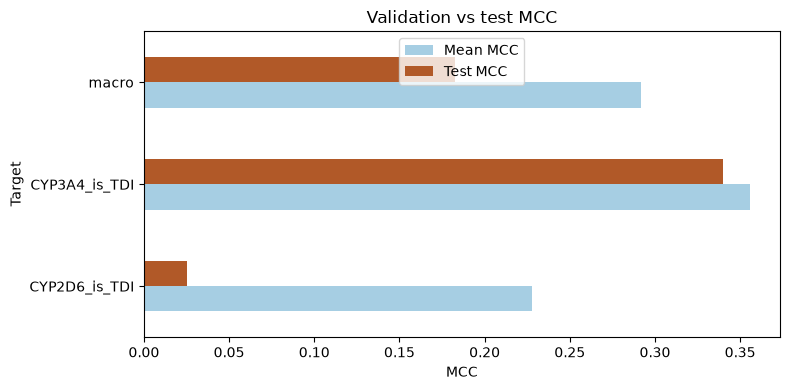

In [167]:
ax = cls_merged.set_index('target')[['mean_mcc', 'MCC_test']].plot(
    kind='barh',
    figsize=(8, 4),
    width=0.5,
    colormap='Paired'
)
ax.set_xlabel('MCC')
ax.set_ylabel('Target')
ax.set_title("Validation vs test MCC")
ax.legend(
    ['Mean MCC', 'Test MCC'],
    loc='upper center'
)
plt.tight_layout()
plt.show()

**Conclusions** : The model failed to generalize on CYP2D6 target in classification resulting in a sharp drop of test macro MCC. For regression the difference was not that significat between the validation and test.

# Final Notes

### Hyperparameters barely matter for regression 

-> our observations and ANOVA test confirmed that for the regression task the MACRO scores remain similar across all configurations suggesting that the finetuning architecture does not have a big impact on the model. 

This can suggest that the dataset can be a limitation here - additional training, tuning parameters and changing redout architectures does not improve the scores significantly, suggesting that the problem may not lie in the model but in the task itself


### Readout architecture and freezing strategy are the most important choices 

-> Specifically for classification tasks we observed that the performance increases significantly when unfreezing the encoder for the linear head (the MLP head does not benefit that much from end to end tuning). 

-> MLP head turned out to outperform the linear head 

### Best run vs best config

-> the best individual run and the config with the best average score across seeds were not always the same

We used the average across 3 seeds to compare configurations, rather than selecting a configuration only because it produced 1 strong run (still the 3 seeds provide limited evidence about these configuration's performance reliability)

### Other parameters dont make a difference

-> While readout and freezing strategy can have a significant impact on the results, tuning dropout or weight decay does not impact the results that strongly 

### Epoch budget limitation

-> We found that setting up a budget of 20 epochs may be not enough for some configurations to properly finish training, especially for the linear readout. Since in both tasks the winning configurations were MLP heads (which did not require additional epochs), we treat this as a limitation rather than an indication to rerun all experiments.

### Test performance and target analysis

-> We discovered that for both tasks some targets are easier for the model than others. Especially problematic target turned out to be CYP2D6 being responsible for the sharp descrease of the test score for classification. In classification one source of this problem can be limited training data. However, for regression this was a target with almost the biggest number of training samples. This combined can suggest that this is just a hard target for the model with not easy to capture behavior.


